Análisis Exploratorio de Ventas Automotrices

Objetivo
Este proyecto tiene como objetivo analizar un conjunto de datos de ventas automotrices para identificar patrones de comercialización, tendencias de mercado y características relevantes de los vehículos más vendidos.

Autor
Román Vicente Lemos Técnico Universitario en Ciencia de Datos



Librerías utilizadas

In [4]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Ignorar advertencias
import warnings
warnings.filterwarnings("ignore")


Carga del conjunto de datos

En esta sección se carga el archivo CSV que contiene la información de ventas automotrices.

In [6]:
df = pd.read_csv("car_sales_data.csv")
#imprime primeras filas 4 filas 
df.head(4)

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Porsche,718 Cayman,4.0,Petrol,2016,57850,49704
2,Ford,Mondeo,1.6,Diesel,2014,39190,24072
3,Toyota,RAV4,1.8,Hybrid,1988,210814,1705


Exploración inicial de los datos

En esta sección se analiza la estructura general del conjunto de datos, incluyendo dimensiones, tipos de datos y estadísticas descriptivas.

In [7]:
# Dimensiones del dataset
df.shape
# Información general
df.info()
# Estadísticas descriptivas
df.describe()
# Nombres de las columnas
list(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50000 non-null  str    
 1   Model                50000 non-null  str    
 2   Engine size          50000 non-null  float64
 3   Fuel type            50000 non-null  str    
 4   Year of manufacture  50000 non-null  int64  
 5   Mileage              50000 non-null  int64  
 6   Price                50000 non-null  int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 2.7 MB


['Manufacturer',
 'Model',
 'Engine size',
 'Fuel type',
 'Year of manufacture',
 'Mileage',
 'Price']

4. Calidad de los datos

Se analizan posibles valores nulos y registros duplicados.

In [18]:
df.isnull().sum()



Manufacturer           0
Model                  0
Engine size            0
Fuel type              0
Year of manufacture    0
Mileage                0
Price                  0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(12)

5. Análisis exploratorio de datos

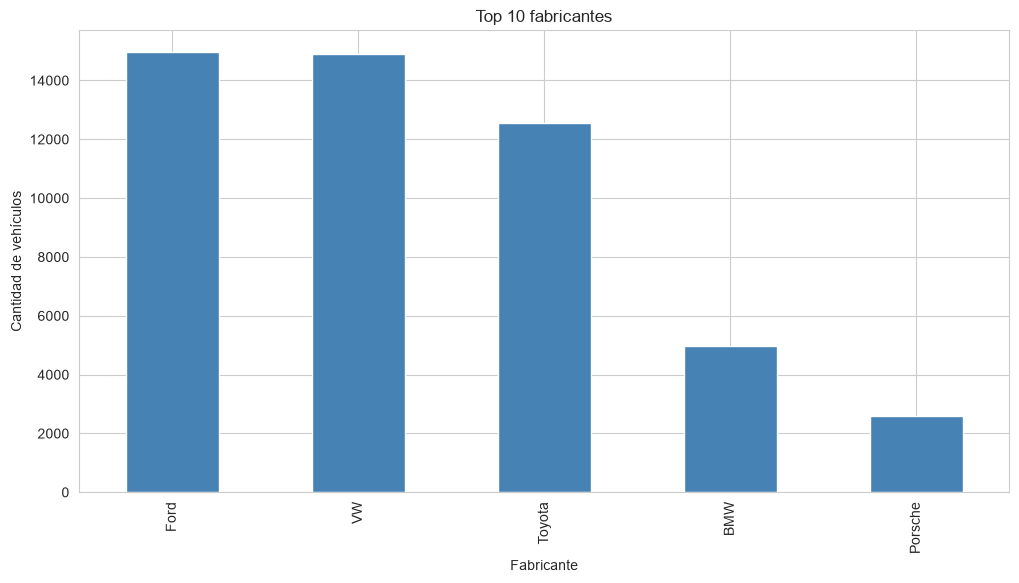

In [20]:
# Cantidad de vehículos por fabricante
df["Manufacturer"].value_counts().head(10).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 10 fabricantes")
plt.xlabel("Fabricante")
plt.ylabel("Cantidad de vehículos")
plt.show()

El análisis de la distribución de vehículos por fabricante muestra que Ford y Volkswagen son las marcas con mayor representación dentro del conjunto de datos, acumulando aproximadamente 15.000 registros cada una.

Toyota ocupa el tercer lugar con cerca de 12.500 vehículos registrados, mientras que BMW y Porsche presentan una participación considerablemente menor.

Esta distribución sugiere que el mercado analizado está dominado por fabricantes de gran volumen, especialmente marcas orientadas al segmento masivo. Por otra parte, los fabricantes premium como BMW y Porsche poseen una menor presencia, lo que podría explicarse por una menor cantidad de unidades comercializadas y precios más elevados.

A partir de estos resultados, resulta interesante analizar si existe una relación entre la participación de una marca en el mercado y el precio promedio de sus vehículos. 

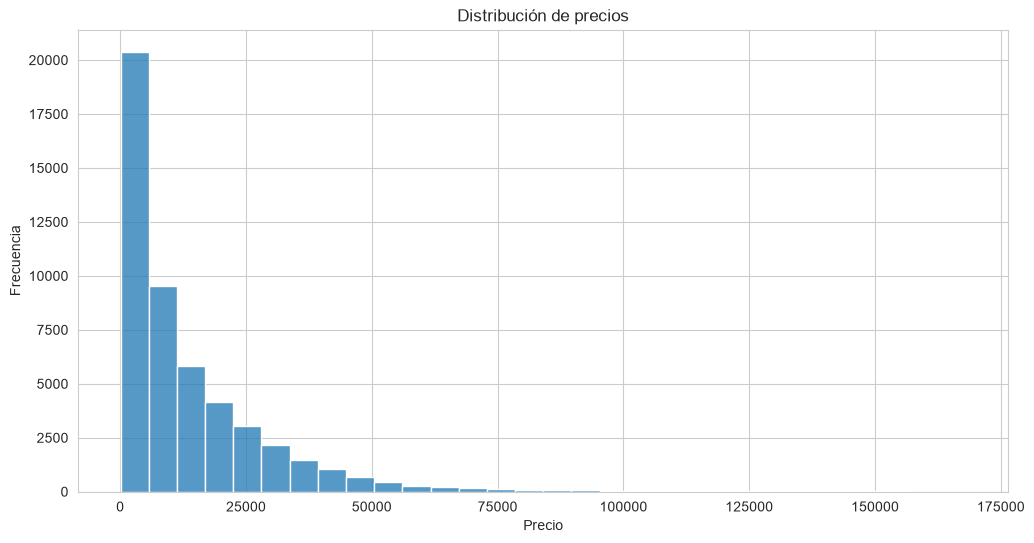

In [21]:
sns.histplot(df["Price"], bins=30)

plt.title("Distribución de precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

La distribución de precios presenta una marcada asimetría hacia la derecha. La mayor parte de los vehículos se concentra en los rangos de precios más bajos, mientras que la cantidad de vehículos disminuye progresivamente a medida que aumenta el precio.

Además, se observa una cola larga hacia los valores más elevados, lo que indica la presencia de vehículos de alta gama con precios considerablemente superiores al promedio del mercado.

Este comportamiento sugiere que el conjunto de datos está compuesto principalmente por automóviles de segmentos económicos y medios, mientras que los vehículos premium representan una proporción reducida del total.

La distribución no parece seguir un patrón normal, por lo que medidas como la mediana podrían resultar más representativas que la media para describir el precio típico de los vehículos analizados.

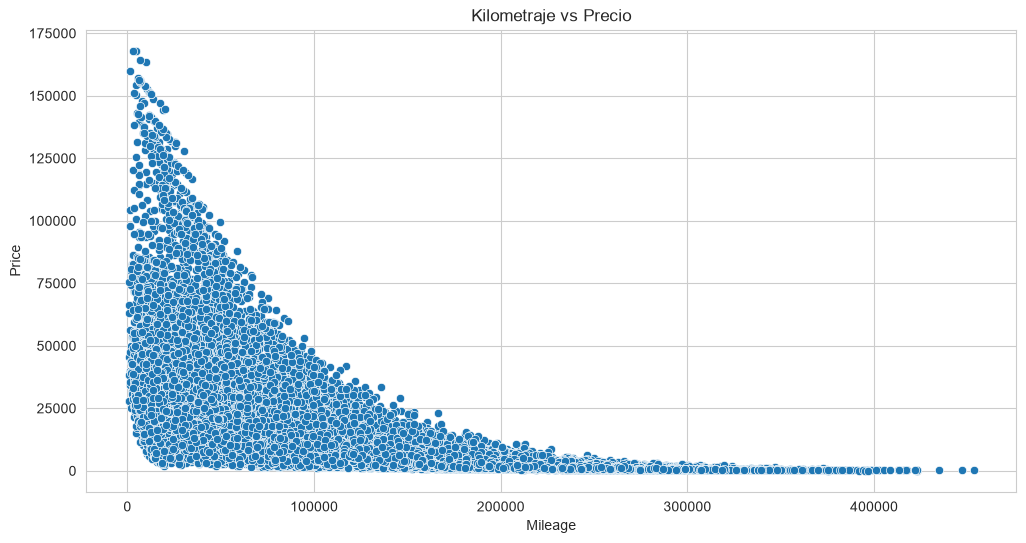

In [22]:
sns.scatterplot(
    data=df,
    x="Mileage",
    y="Price"
)

plt.title("Kilometraje vs Precio")
plt.show()

El gráfico de dispersión muestra una relación inversa entre el kilometraje y el precio de los vehículos. En términos generales, a medida que aumenta la cantidad de kilómetros recorridos, el valor de mercado del vehículo tiende a disminuir.

Se observa una alta concentración de vehículos con kilometrajes bajos y medios, donde también se encuentran los precios más elevados. Por el contrario, los vehículos que superan los 200.000 kilómetros presentan valores considerablemente menores y una menor dispersión de precios.

Además, se identifican algunos vehículos con precios elevados pese a tener un kilometraje relativamente alto, lo que podría estar asociado a factores como la marca, el modelo, el año de fabricación o características específicas no representadas en este gráfico.

Estos resultados sugieren que el kilometraje es una variable relevante para explicar el precio de un vehículo, aunque no es el único factor que influye en su valor final.

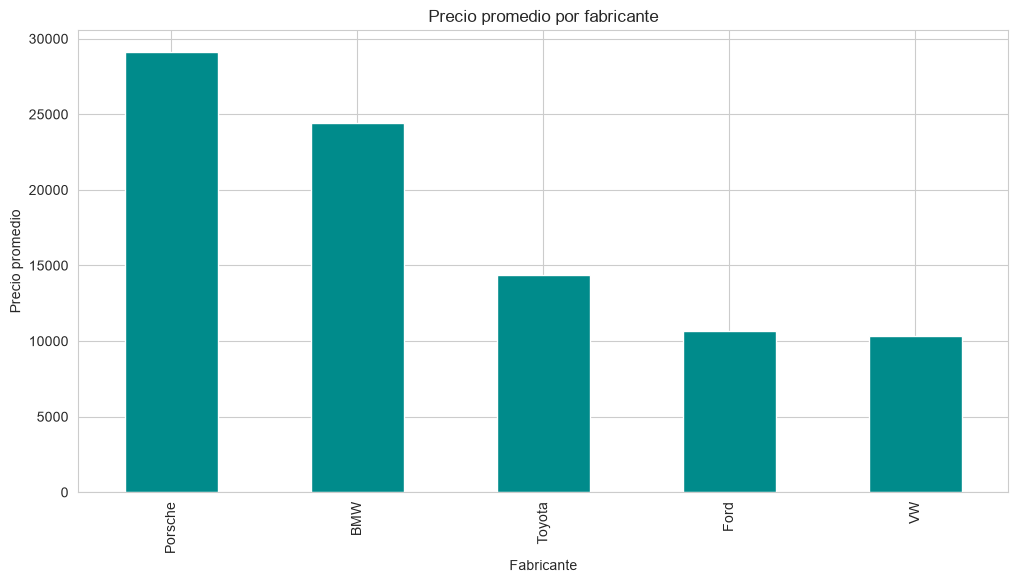

In [8]:

# Precio promedio por fabricante

precio_marca = (
    df.groupby("Manufacturer")["Price"]
    .mean()
    .sort_values(ascending=False)
)

precio_marca.plot(
    kind="bar",
    color="darkcyan"
)

plt.title("Precio promedio por fabricante")
plt.xlabel("Fabricante")
plt.ylabel("Precio promedio")
plt.show()

El análisis del precio promedio por fabricante revela diferencias significativas entre las distintas marcas presentes en el conjunto de datos.

Porsche registra el precio promedio más elevado, superando ampliamente al resto de los fabricantes analizados. BMW ocupa el segundo lugar, lo que evidencia la presencia de vehículos orientados al segmento premium.

Por otro lado, Toyota presenta un precio promedio intermedio, mientras que Ford y Volkswagen registran los valores más bajos dentro de las marcas analizadas.

Estos resultados sugieren una segmentación del mercado en función del posicionamiento de cada fabricante. Las marcas premium concentran vehículos de mayor valor económico, mientras que las marcas generalistas presentan una oferta más accesible para un público amplio.

A partir de este análisis, sería interesante investigar si estas diferencias de precio están relacionadas con variables como el año de fabricación, el kilometraje o el tipo de combustible.

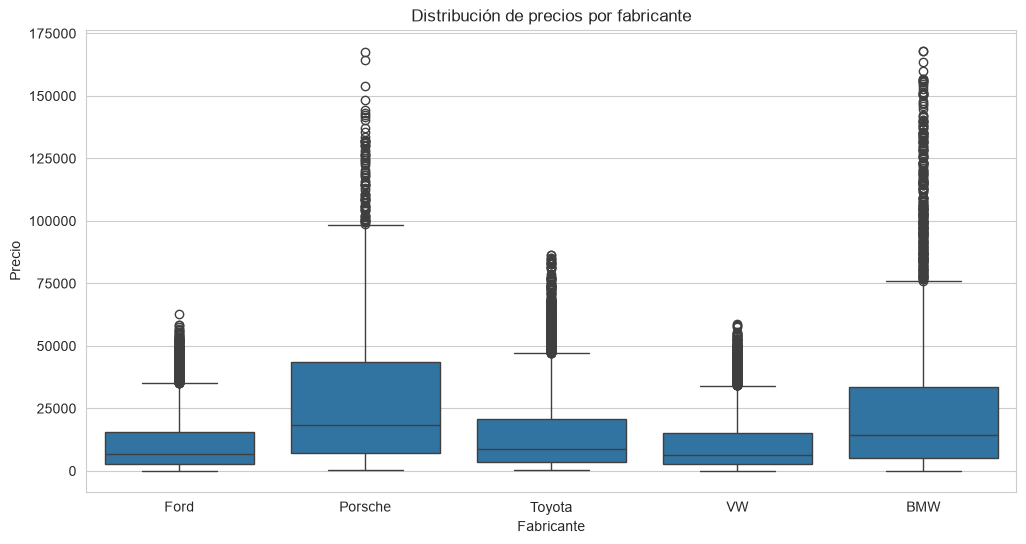

In [9]:
sns.boxplot(
    data=df,
    x="Manufacturer",
    y="Price"
)

plt.title("Distribución de precios por fabricante")
plt.xlabel("Fabricante")
plt.ylabel("Precio")
plt.show()

La distribución de precios por fabricante muestra diferencias notables entre las marcas analizadas.

Porsche y BMW presentan las medianas de precio más elevadas, lo que confirma su posicionamiento dentro del segmento premium del mercado automotriz. Además, ambas marcas muestran una amplia dispersión de precios, indicando la existencia de modelos con características y valores muy variados.

Toyota presenta precios intermedios y una variabilidad moderada, mientras que Ford y Volkswagen concentran gran parte de sus vehículos en rangos de precios más bajos.

También se observan numerosos valores atípicos (outliers) en todas las marcas, especialmente en Porsche y BMW. Estos registros corresponden a vehículos con precios significativamente superiores al resto y podrían representar versiones de alta gama o unidades con características particulares.

En términos generales, los resultados evidencian una segmentación clara entre fabricantes orientados al mercado masivo y fabricantes enfocados en el segmento premium.

In [10]:
#correlacion n7umerica entre kilometrage y precio

df["Mileage"].corr(df["Price"])

np.float64(-0.6326917540945916)

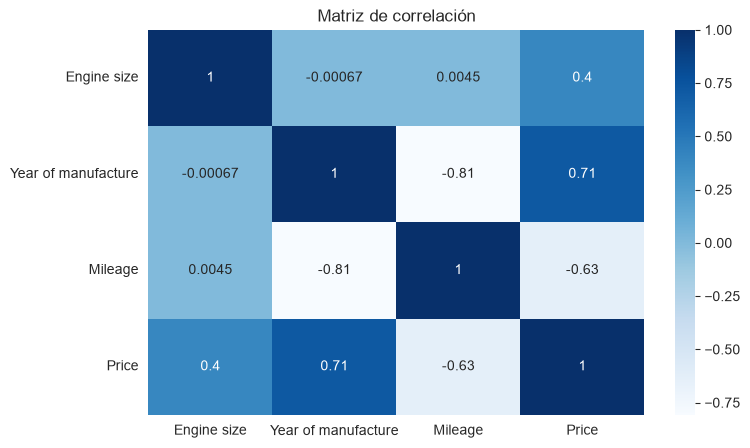

In [11]:
#matriz de correlacion 
plt.figure(figsize=(8,5))

sns.heatmap(
    df[["Engine size", "Year of manufacture", "Mileage", "Price"]].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Matriz de correlación")
plt.show()

La matriz de correlación permite identificar la intensidad y dirección de la relación entre las variables numéricas del conjunto de datos.

La relación más fuerte observada corresponde al año de fabricación y el kilometraje (-0.81), indicando que los vehículos más recientes suelen registrar una menor cantidad de kilómetros recorridos.

Asimismo, el precio presenta una correlación positiva fuerte con el año de fabricación (0.71), lo que sugiere que los vehículos más nuevos tienden a tener un mayor valor de mercado.

Por otro lado, existe una correlación negativa moderadamente fuerte entre el kilometraje y el precio (-0.63), evidenciando que el aumento en la cantidad de kilómetros recorridos suele asociarse con una disminución del precio del vehículo.

El tamaño del motor presenta una correlación positiva moderada con el precio (0.40), lo que indica que los vehículos con motores de mayor cilindrada tienden a ser más costosos, aunque esta relación no resulta tan determinante como el año de fabricación o el kilometraje.

En conclusión, las variables con mayor influencia sobre el precio de los vehículos son el año de fabricación y el kilometraje, mientras que el tamaño del motor tiene un impacto más limitado.

Hallazgos principales

Ford y Volkswagen son las marcas con mayor cantidad de vehículos registrados.
Porsche presenta el precio promedio más alto del conjunto de datos.
BMW ocupa el segundo lugar en términos de precio promedio.
La distribución de precios se concentra en vehículos de bajo y mediano valor.
Existe una correlación negativa fuerte entre kilometraje y precio (-0.63).
El año de fabricación presenta una correlación positiva fuerte con el precio (0.71).
Los vehículos más recientes suelen registrar menos kilometraje (-0.81).

Conclusiones

El análisis exploratorio permitió identificar patrones relevantes dentro del mercado automotriz representado en el conjunto de datos.

Las marcas generalistas, especialmente Ford y Volkswagen, concentran la mayor cantidad de vehículos, mientras que Porsche y BMW destacan por sus precios promedio significativamente superiores.

La edad del vehículo y el kilometraje aparecen como los principales factores asociados al precio. Los vehículos más nuevos tienden a conservar mejor su valor, mientras que el incremento del kilometraje provoca una depreciación considerable.

Finalmente, los resultados obtenidos muestran que el análisis de datos permite comprender los factores que influyen en el valor de mercado de los vehículos y facilita la identificación de tendencias relevantes para la toma de decisiones comerciales.